### This notebook contains

- The parameters and basic usage of the oblate, ring, and egg models.
- Kepler-167e light curves with illustrative projected shapes.
- Shape signals relative to a spherical planet with the same projected area.


#### Oblate model

We use `oblate_lc` from `JoJo` to calculate an oblate planet's transit. The transit parameter array contains 11 values, in this order:

- $t_c$: the reference transit time (day).
- $b$: the transit impact parameter.
- $P$: the orbital period (day).
- $r_{\mathrm{me}}$: the equal-area radius in stellar-radius units, $r_{\mathrm{me}}=\sqrt{r_{\mathrm{eq}}r_{\mathrm{pol}}}$.
- $f$: the projected oblateness, $1-r_{\mathrm{pol}}/r_{\mathrm{eq}}$.
- $\theta$: the projected orientation angle (radians).
- $e$: the orbital eccentricity.
- $\omega$: the argument of periastron (radians).
- $u_1,u_2$: the quadratic limb-darkening coefficients.
- $\log_{10}\rho_\star$: the stellar density in $\mathrm{g\,cm^{-3}}$.

The other arguments are `time_array` (days), `photo_ecc` (False for Kepler positions; True for the near-transit constant-velocity approximation), `exp_time` (days), `supersample_factor` (exposure midpoint samples, default 5), and `n_step` (Gauss–Legendre nodes per boundary arc, default 64). A zero exposure gives instantaneous flux; `None` infers the cadence. All examples below use the same explicit one-minute exposure.


Let us take Kepler-167e as an example and calculate the light curve assuming the oblateness is $0.1$ and obliquity is $45^{\circ}$

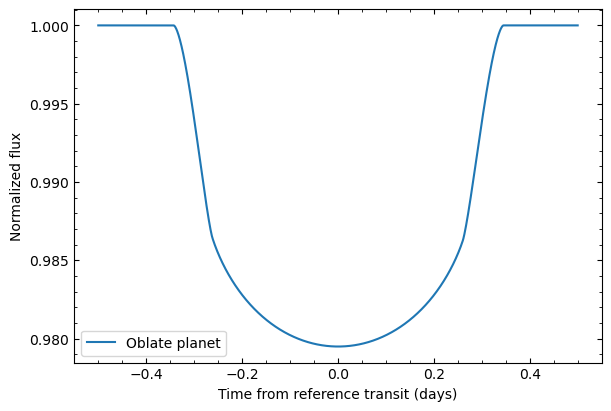

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from JoJo import oblate_lc, spherical_lc

FIGSIZE = (6, 4)  # Shared canvas size for every figure in this notebook.

t = np.arange(-0.5, 0.5, 1 / 60 / 24)
exp_time = 1 / 60 / 24
# Kepler-167e orbital, stellar, and radius parameters, as in the original example.
# Kipping et al. (2016); the projected shapes below are illustrative assumptions.
pars = [0, 0.233, 1071.23228, 0.1281, 0.1, np.pi / 4,
        0.062, np.deg2rad(201), 0.6226, 0.0498, 0.46]
kepler167e = pars.copy()
f_ob, t_con_ob = oblate_lc(pars, t, exp_time=exp_time)

fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
ax.plot(t, f_ob, label="Oblate planet")
ax.set_xlabel("Time from reference transit (days)")
ax.set_ylabel("Normalized flux")
ax.legend()
plt.show()


We can also use ```spherical_lc``` to generate the light curve of a perfectly spherical planet with the same cross-section. The oblateness signal is defined as the difference of their light curves.

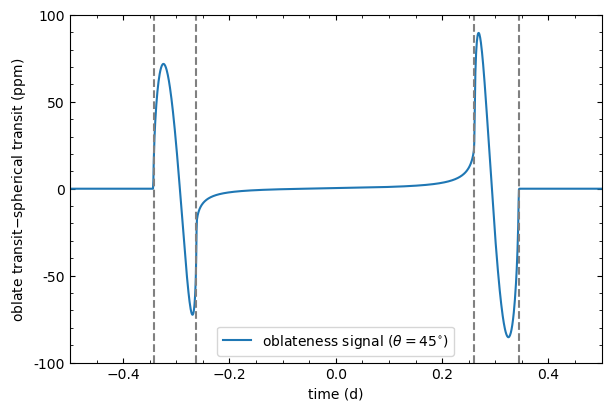

In [13]:
f_sp, t_con_sp = spherical_lc(pars, t, exp_time=exp_time)

fig, ax = plt.subplots(1, 1, figsize=FIGSIZE, layout="constrained")
ax.plot(t, f_ob-f_sp, label=r'oblateness signal ($\theta=45^{\circ}$)')
for t_i in t_con_ob:
    ax.axvline(t_i, ls='--', c='grey')

ax.set_xlabel('time (d)')
ax.set_ylabel('oblate transit$-$spherical transit (ppm)')
ax.set_yticks([0.0001, 0.00005, 0., -0.00005, -0.0001])
y_tick_labels = ['100', '50', '0', '-50', '-100']
ax.set_yticklabels(y_tick_labels)
ax.set_xlim(-0.5, 0.5)
plt.legend()
plt.show()

The shape of the oblateness signal primarily relies on the impact parameter $b$ and the obliquity $\theta$. When $b\neq0$, and $\theta\neq 0^{\circ}$ or $90^{\circ}$, the oblateness signal is asymmetrical. The figures illustrate distinct oblateness signals corresponding to different obliquities.

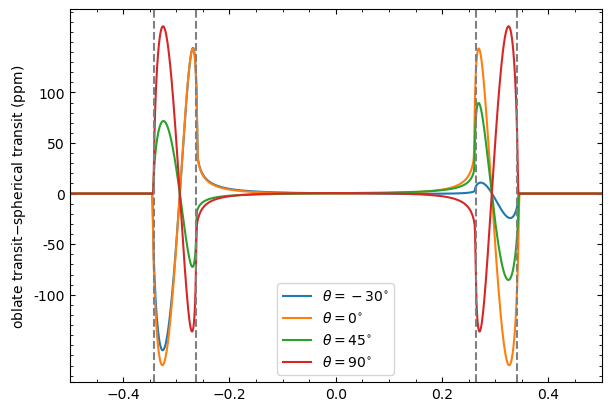

In [14]:
fig, ax = plt.subplots(1, 1, figsize=FIGSIZE, layout="constrained")
#color = ['limegreen', 'red', 'royalblue']
theta = [-30, 0, 45, 90]
for i in range(len(theta)):
    pars = kepler167e.copy()
    pars[5] = theta[i]*np.pi/180
    f_ob, t_con_ob = oblate_lc(pars, t, exp_time=exp_time)
    f_sp, t_con_sp = spherical_lc(pars, t, exp_time=exp_time)
    lab = r'$\theta={}$'.format(theta[i])
    ax.plot(t, f_ob-f_sp, label=lab+r'$^{\circ}$')

for t_i in t_con_ob:
    ax.axvline(t_i, ls='--', color='grey')
    
ax.set_ylabel('oblate transit$-$spherical transit (ppm)')
ax.set_yticks([0.0001, 0.00005, 0., -0.00005, -0.0001])
y_tick_labels = ['100', '50', '0', '-50', '-100']
ax.set_yticklabels(y_tick_labels)
ax.set_xlim(-0.5, 0.5)
plt.legend()
plt.show()

#### Ring model

With `ring_lc` from `JoJo`, we calculate the transit of a spherical planet surrounded by a ring. The transit parameter array contains 14 values, in this order:

- $t_c,b,P$: the same transit time, impact parameter, and period as above.
- $r_p$: the spherical planet radius in stellar-radius units.
- $r_{\mathrm{in}},r_{\mathrm{out}}$: the inner and outer equatorial ring radii in stellar-radius units.
- $f_r$: the projected ring flattening, so the minor-to-major axis ratio is $q=1-f_r$. For a circular thin ring tilted by $i_r$ from face-on, $q=\cos i_r$; this argument is **not** an angle.
- $\theta_r$: the projected ring orientation (radians).
- $e,\omega,u_1,u_2,\log_{10}\rho_\star$: the same orbital and stellar parameters as above.
- opacity: the blocked fraction of light behind the ring, between 0 and 1.

Unlike `oblate_lc` and `egg_lc`, `ring_lc` returns only the flux array. The exposure and quadrature settings have the same meaning.


We keep the Kepler-167e orbit, stellar parameters, and planet radius $r_p=0.1281$, and add an illustrative opaque ring with $r_{\mathrm{in}}=1.5r_p$, $r_{\mathrm{out}}=2r_p$, $f_r=0.25$, and $\theta_r=45^\circ$. These ring parameters are assumptions, not a measured ring around Kepler-167e.

Here $r_{\mathrm{in}}(1-f_r)>r_p$, so the planet fits entirely within the projected inner hole and there is no planet/ring overlap. The equal-area spherical radius is therefore

$$r_{\mathrm{eff}}=\sqrt{r_p^2+(1-f_r)(r_{\mathrm{out}}^2-r_{\mathrm{in}}^2)}.$$

We use opacity 1 so this is the actual geometric occulting area, and we can estimate the difference between the light curve due to a ring model and a spherical model with the same area.


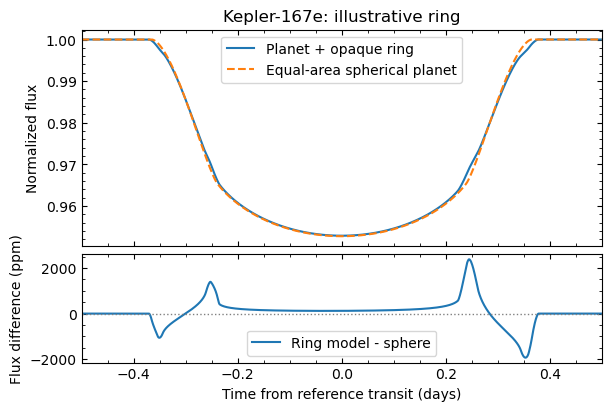

In [15]:
from JoJo import ring_lc

tc, impact, period, rp, _, _, ecc, omega, u1, u2, density = kepler167e
r_in, r_out = 1.5 * rp, 2.0 * rp
f_ring, theta_ring, opacity = 0.25, np.pi / 4, 1.0
assert r_in * (1 - f_ring) > rp  # No projected planet/ring overlap.
parr = [tc, impact, period, rp, r_in, r_out, f_ring, theta_ring,
        ecc, omega, u1, u2, density, opacity]
f_r = ring_lc(parr, t, exp_time=exp_time)

rp_eff_ring = np.sqrt(rp**2 + (1 - f_ring) * (r_out**2 - r_in**2))
par_eff_ring = [tc, impact, period, rp_eff_ring, 0, 0,
                ecc, omega, u1, u2, density]
f_sp_ring, _ = spherical_lc(par_eff_ring, t, exp_time=exp_time)
assert np.isfinite(f_r).all() and np.isfinite(f_sp_ring).all()

fig, axs = plt.subplots(2, 1, figsize=FIGSIZE, sharex=True,
                        gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")
axs[0].plot(t, f_r, label="Planet + opaque ring")
axs[0].plot(t, f_sp_ring, "--", label="Equal-area spherical planet")
axs[0].set_ylabel("Normalized flux")
axs[0].set_title("Kepler-167e: illustrative ring")
axs[0].legend()
axs[1].plot(t, 1e6 * (f_r - f_sp_ring), label="Ring model - sphere")
axs[1].axhline(0, color="grey", ls=":", lw=1)
axs[1].set_xlabel("Time from reference transit (days)")
axs[1].set_ylabel("Flux difference (ppm)")
axs[1].set_xlim(t[0], t[-1])
axs[1].legend()
plt.show()


The upper panel compares both light curves; the lower panel shows $10^6(F_{\mathrm{ring}}-F_{\mathrm{sphere}})$ in ppm. The comparison holds the orbital and stellar parameters fixed and changes only the occulting shape and the comparison sphere's radius. Equal projected area does not imply identical transit depth on a limb-darkened star, because different shapes cover different stellar intensities. This is a fixed-parameter shape signal, not a residual after fitting a spherical transit model.


#### Egg model

With `egg_lc` from `JoJo`, we calculate a planet formed by joining two half-ellipses with a shared vertical semi-axis. The transit parameter array contains 12 values, in this order:

- $t_c,b,P$: the same transit time, impact parameter, and period as above.
- $a_+$: the horizontal semi-axis of the right half-ellipse in the planet's local frame.
- $a_-$: the horizontal semi-axis of the left half-ellipse in the planet's local frame.
- $b_{\mathrm{egg}}$: their shared vertical semi-axis; this is distinct from the transit impact parameter $b$.
- $\theta$: the projected orientation of the joined shape (radians).
- $e,\omega,u_1,u_2,\log_{10}\rho_\star$: the same orbital and stellar parameters as above.

All three shape axes are in stellar-radius units. The function returns `(flux, sampled_contacts)`, like `oblate_lc`. Equal halves ($a_+=a_-$) recover an ellipse. Partial occultation currently supports two boundary intersections.

For an illustrative asymmetry, we take $a_+=1.15r_0$, $a_-=0.95r_0$, $b_{\mathrm{egg}}=r_0/1.05$, and $\theta=45^\circ$, with $r_0=0.1281$. The orbit and star are unchanged. The projected area and equal-area spherical radius are

$$A_{\mathrm{egg}}=\frac{\pi}{2}b_{\mathrm{egg}}(a_++a_-),\qquad r_{\mathrm{eff}}=\sqrt{\frac{b_{\mathrm{egg}}(a_++a_-)}{2}}.$$

This choice preserves $r_{\mathrm{eff}}=r_0$, so the egg has the same area as the original Kepler-167e comparison planet.


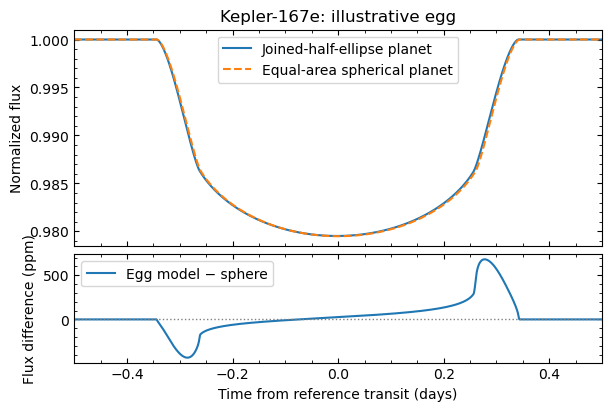

In [16]:
from JoJo import egg_lc

r0 = kepler167e[3]
a_plus, a_minus, b_egg = 1.15 * r0, 0.95 * r0, r0 / 1.05
theta_egg = np.pi / 4
pare = [tc, impact, period, a_plus, a_minus, b_egg, theta_egg,
        ecc, omega, u1, u2, density]
f_egg, t_con_egg = egg_lc(pare, t, exp_time=exp_time)

rp_eff_egg = np.sqrt(b_egg * (a_plus + a_minus) / 2)
assert np.isclose(rp_eff_egg, r0)
par_eff_egg = [tc, impact, period, rp_eff_egg, 0, 0,
               ecc, omega, u1, u2, density]
f_sp_egg, _ = spherical_lc(par_eff_egg, t, exp_time=exp_time)
assert np.isfinite(f_egg).all() and np.isfinite(f_sp_egg).all()

fig, axs = plt.subplots(2, 1, figsize=FIGSIZE, sharex=True,
                        gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")
axs[0].plot(t, f_egg, label="Joined-half-ellipse planet")
axs[0].plot(t, f_sp_egg, "--", label="Equal-area spherical planet")
axs[0].set_ylabel("Normalized flux")
axs[0].set_title("Kepler-167e: illustrative egg")
axs[0].legend()
axs[1].plot(t, 1e6 * (f_egg - f_sp_egg), label="Egg model − sphere")
axs[1].axhline(0, color="grey", ls=":", lw=1)
axs[1].set_xlabel("Time from reference transit (days)")
axs[1].set_ylabel("Flux difference (ppm)")
axs[1].set_xlim(t[0], t[-1])
axs[1].legend()
plt.show()


The lower panel shows $10^6(F_{\mathrm{egg}}-F_{\mathrm{sphere}})$ in ppm with the same exposure averaging. It isolates the fixed-parameter shape difference, including the effect of unequal halves; it is not a best-fit spherical-model residual.
